# Handwritten digit recognition: learn by doing

**Goal:** use the real MNIST dataset and an already trained neural network to recognize digits from 0 to 9. This notebook follows the supplied page, in simple English.

Run each code cell from top to bottom. Open this notebook inside the extracted `mnist-hands-on` folder. Install `numpy` and `Pillow` with `python -m pip install -r requirements.txt` first.

The saved outputs below come from an actual execution with MNIST and the book's trained weights. You can edit the sample indices and run the cells yourself.


## 1. What is the problem?

We give the network a handwritten digit image. It produces ten probabilities: one for each digit from **0 to 9**. The digit with the largest probability is the prediction.

Training has already been completed. The saved **weights and biases** are the trained parameters. Using them to calculate a prediction is called **inference**, or **forward propagation**.

This lesson loads those parameters in Section 7. Loading images in the next section only reads the dataset.


## 2. Load the same MNIST dataset

MNIST contains handwritten digits from **0 to 9**: **60,000 training images** and **10,000 test images**. We use the original `dataset/mnist.py` loader from the book.

| Variable | What it contains |
| --- | --- |
| `x_train` | Training images |
| `t_train` | Actual digit labels for the training images |
| `x_test` | Test images |
| `t_test` | Actual digit labels for the test images |

`flatten=True` stores an image as one row of **784 pixel values**. `normalize=False` keeps its original values from **0 to 255**. `one_hot_label=False` keeps each label as one digit.


In [1]:
from pathlib import Path
import pickle
import numpy as np
from PIL import Image
from dataset.mnist import load_mnist

(x_train, t_train), (x_test, t_test) = load_mnist(
    flatten=True,
    normalize=False,
    one_hot_label=False,
)

print('x_train:', x_train.shape)
print('t_train:', t_train.shape)
print('x_test: ', x_test.shape)
print('t_test: ', t_test.shape)


x_train: (60000, 784)
t_train: (60000,)
x_test:  (10000, 784)
t_test:  (10000,)


`(60000, 784)` means **60,000 images**, with **784 values per image**. `(60000,)` means **60,000 labels** in a one-dimensional array. The test arrays have the same structure, with **10,000** examples.


## 3. Inspect one image and its label

Each image has **28 × 28 = 784 pixels**, with one grayscale channel. An original pixel value is between **0 and 255**: 0 is black, 255 is white, and values between them are shades of gray.

Each image has an actual label from **0 to 9**. The first training image is at index `0`, and its actual label is `5`.


In [2]:
train_index = 0
img = x_train[train_index]
label = t_train[train_index]

print('Actual digit:', int(label))
print('Flat image shape:', img.shape)
print('Number of pixels:', img.size)
print('Smallest pixel value:', int(img.min()))
print('Largest pixel value: ', int(img.max()))

img = img.reshape(28, 28)
print('Image shape after reshape:', img.shape)


Actual digit: 5
Flat image shape: (784,)
Number of pixels: 784
Smallest pixel value: 0
Largest pixel value:  255
Image shape after reshape: (28, 28)


`reshape(28, 28)` puts the **same 784 values** back into 28 rows and 28 columns. It changes the arrangement, so we can display the image. It does not change the pixel values.


## 4. Display the image with Pillow

`Image.fromarray(np.uint8(img))` converts the pixel array into a Pillow image. In a Python script, the page uses `.show()` to open it. In this notebook, the last image expression appears directly below the cell.

We enlarge the display for readability; the underlying MNIST array stays **28 × 28**.


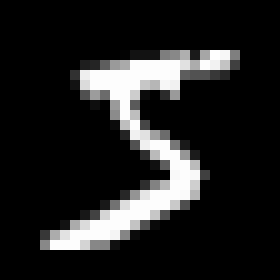

In [3]:
pil_img = Image.fromarray(np.uint8(img))
pil_img.resize((280, 280), Image.Resampling.NEAREST)


The printed label should agree with the visible digit. The label tells us the correct answer from the dataset; it is not yet a network prediction.

Here is a small **5 × 5 region** from this actual image. Its values describe the brightness of those pixels. The small pixel table in the supplied page is only an example; these are the values from our selected MNIST image.


In [4]:
print(img[10:15, 10:15])


[[  1 154 253  90   0]
 [  0 139 253 190   2]
 [  0  11 190 253  70]
 [  0   0  35 241 225]
 [  0   0   0  81 240]]


## 5. Pixel values and normalization

Normalization changes pixel values from **0–255** to **0–1** by dividing by 255.

`normalized_pixel = original_pixel / 255`

Thus 0 becomes 0.0, and 255 becomes 1.0. The image still represents the same digit.

The page loads unnormalized data for displaying the image. For inference, we use the same normalization setting used by the trained network. The book's inference example uses `normalize=True`.


In [5]:
img_normalized = img.astype(np.float32) / 255.0

print('Original pixel range:  ', int(img.min()), 'to', int(img.max()))
print('Normalized pixel range:', float(img_normalized.min()), 'to', float(img_normalized.max()))

# Select a real pixel with a value between black and white.
row, col = np.argwhere((img > 0) & (img < 255))[0]
raw_pixel = int(img[row, col])
scaled_pixel = float(img_normalized[row, col])
print(f'Pixel at row {row}, column {col}: {raw_pixel} / 255 = {scaled_pixel:.6f}')


Original pixel range:   0 to 255
Normalized pixel range: 0.0 to 1.0
Pixel at row 5, column 12: 3 / 255 = 0.011765


## 6. Understand the three loader options

| Option | `True` | `False` |
| --- | --- | --- |
| `normalize` | Pixel values from 0.0 to 1.0 | Original values from 0 to 255 |
| `flatten` | One flat array of 784 values per image | Retain image dimensions, including the grayscale channel |
| `one_hot_label` | Ten values per label, with one position set to 1 | One digit per label |

**A detail of this exact loader:** with `flatten=False`, an image has shape `(1, 28, 28)`. The complete training array has shape `(60000, 1, 28, 28)`. The `1` is the grayscale channel; the image still has 28 rows and 28 columns.


In [6]:
(x_images, t_digits), (_, _) = load_mnist(
    normalize=False,
    flatten=False,
    one_hot_label=False,
)

print('Training image array:', x_images.shape)
print('One image:           ', x_images[0].shape)
print('Its single label:    ', int(t_digits[0]))

# Release these arrays after inspecting their shapes.
del x_images, t_digits, _


Training image array: (60000, 1, 28, 28)
One image:            (1, 28, 28)
Its single label:     5


In [7]:
(_, t_one_hot), (_, _) = load_mnist(
    normalize=False,
    flatten=True,
    one_hot_label=True,
)

print('Training label array:', t_one_hot.shape)
print('First label as ten values:', t_one_hot[0])
print('Position of its 1:', int(np.argmax(t_one_hot[0])))

del t_one_hot, _


Training label array: (60000, 10)
First label as ten values: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
Position of its 1: 5


The first label is **5**, so its one-hot version has a `1` at position **5**. Positions are numbered from **0 to 9**. We will use the simpler single-digit labels for the final comparison.


## 7. Use the trained network to predict a digit

This is a **10-class classification** problem. The output layer has **10 neurons**, corresponding to `y_0` through `y_9`.

The calculation follows the book's trained-network example: use the saved weights and biases, apply the hidden-layer activation functions, and use **softmax** at the output to obtain ten probabilities.

We choose the digit whose probability is largest. For example, if the largest value is at position 2, the predicted digit is **2**.

The probabilities printed in the supplied page are illustrative. Below, we calculate real probabilities for **test image 1**, whose actual label is **2**. This is a different image from the first training image, which was **5**.


In [8]:
# These are the book's already trained weights and biases.
with open(Path('assets') / 'sample_weight.pkl', 'rb') as file:
    network = pickle.load(file)

# Load pixel values in the form expected by that trained network.
(x_train_normalized, t_train_normalized), (x_test_normalized, t_test_normalized) = load_mnist(
    normalize=True,
    flatten=True,
    one_hot_label=False,
)

print('Trained parameters loaded.')
print('Test input shape:', x_test_normalized.shape)
print('Test pixel range:', float(x_test_normalized.min()), 'to', float(x_test_normalized.max()))


Trained parameters loaded.
Test input shape: (10000, 784)
Test pixel range: 0.0 to 1.0


In [9]:
def sigmoid(a):
    return 1 / (1 + np.exp(-a))


def softmax(a):
    # Subtracting the largest value keeps the calculation stable.
    exp_a = np.exp(a - np.max(a))
    return exp_a / np.sum(exp_a)


def predict(network, x):
    W1, W2, W3 = network['W1'], network['W2'], network['W3']
    b1, b2, b3 = network['b1'], network['b2'], network['b3']

    a1 = np.dot(x, W1) + b1
    z1 = sigmoid(a1)

    a2 = np.dot(z1, W2) + b2
    z2 = sigmoid(a2)

    a3 = np.dot(z2, W3) + b3
    return softmax(a3)


`predict` is the forward propagation calculation. The saved parameters are used to produce the output; they are not updated here.

The final line applies softmax to the ten output values. `np.argmax` below returns the **position** of the largest probability, which is the predicted digit.


Actual digit: 2
Output shape: (10,)

Digit   Probability
    0   0.004836
    1   0.001105
    2   0.944252
    3   0.014309
    4   0.000001
    5   0.006676
    6   0.027533
    7   0.000001
    8   0.001286
    9   0.000000

Sum of probabilities: 1.0
Predicted digit: 2


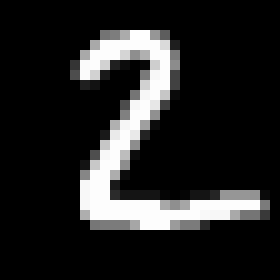

In [10]:
test_index = 1
x = x_test_normalized[test_index]
actual_digit = int(t_test_normalized[test_index])

probabilities = predict(network, x)
predicted_digit = int(np.argmax(probabilities))

print('Actual digit:', actual_digit)
print('Output shape:', probabilities.shape)
print()
print('Digit   Probability')
for digit, probability in enumerate(probabilities):
    print(f'{digit:>5}   {probability:.6f}')

print()
print('Sum of probabilities:', round(float(probabilities.sum()), 6))
print('Predicted digit:', predicted_digit)

# Display the original, unnormalized version of this same test image.
test_img = x_test[test_index].reshape(28, 28)
Image.fromarray(np.uint8(test_img)).resize((280, 280), Image.Resampling.NEAREST)


## 8. Practice with the same dataset

1. Change `train_index = 0` to `train_index = 1`. Run Sections 3–5 again and compare the new label with the displayed image.
2. Read the three loader options again. Match each option with its effect on values, shapes, or labels.
3. Change `test_index = 1` to another test index and rerun the final cell. Compare the actual digit, the largest probability, and the predicted digit.

When you can explain these outputs, keep your code and your observations. They will become the GitHub repository.

## Source credit

- Original dataset loader: [Koki Saitoh / O'Reilly Japan, `dataset/mnist.py`](https://github.com/oreilly-japan/deep-learning-from-scratch/blob/master/dataset/mnist.py).
- Trained weights and forward propagation: [Chapter 3 example](https://github.com/oreilly-japan/deep-learning-from-scratch/blob/master/ch03/neuralnet_mnist.py) and [`sample_weight.pkl`](https://github.com/oreilly-japan/deep-learning-from-scratch/blob/master/ch03/sample_weight.pkl).
- The original MIT license is included at `third_party/KOKI_SAITOH_LICENSE.md`. The lesson's inference function follows the cited example.
